## #31 CNN Project

In [1]:
import tensorflow as tf
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
import matplotlib.pyplot as plt

In [3]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
assert X_train.shape == (50000, 32, 32, 3)
assert X_test.shape == (10000, 32, 32, 3)
assert y_train.shape == (50000, 1)
assert y_test.shape == (10000, 1)

In [4]:
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))

def augment(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.2)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    image = tf.image.random_saturation(image, lower=0.8, upper=1.2)
    image = tf.image.random_hue(image, max_delta=0.2)
    return image, label

def preprocess(image, label):
    image = tf.cast(image, tf.float32)
    image = (image / 127.5) - 1
    image = tf.image.resize(image, (227, 227))
    return image, label

def prepare_dataset(ds, batch_size=100, augment_data=False):
    if augment_data:
        ds = ds.map(augment, num_parallel_calls=tf.data.experimental.AUTOTUNE)
    ds = ds.map(preprocess, num_parallel_calls=tf.data.experimental.AUTOTUNE)
    ds = ds.shuffle(buffer_size=10000).batch(batch_size)
    ds = ds.prefetch(buffer_size=tf.data.experimental.AUTOTUNE)
    return ds

train_ds = prepare_dataset(train_ds, augment_data=True)
test_ds = prepare_dataset(test_ds, augment_data=False)

In [5]:
model = tf.keras.models.Sequential(
    [
        tf.keras.layers.Conv2D(filters=96, kernel_size=(11, 11), strides=(4, 4), activation='relu', kernel_initializer='he_normal', input_shape=(227, 227, 3)),
        tf.keras.layers.MaxPool2D(pool_size=(3, 3), strides=(2, 2)),
        tf.keras.layers.Conv2D(filters=256, kernel_size=(5, 5), strides=(1, 1), activation='relu', kernel_initializer='he_normal', padding='same'),
        tf.keras.layers.MaxPool2D(pool_size=(3, 3), strides=(2, 2)),
        tf.keras.layers.Conv2D(filters=384, kernel_size=(3, 3), strides=(1, 1), activation='relu', kernel_initializer='he_normal', padding='same'),
        tf.keras.layers.Conv2D(filters=384, kernel_size=(3, 3), strides=(1, 1), activation='relu', kernel_initializer='he_normal', padding='same'),
        tf.keras.layers.Conv2D(filters=256, kernel_size=(3, 3), strides=(1, 1), activation='relu', kernel_initializer='he_normal', padding='same'),
        tf.keras.layers.MaxPool2D(pool_size=(3, 3), strides=(2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(4096, activation='relu', kernel_initializer='he_normal'),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(4096, activation='relu', kernel_initializer='he_normal'),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(10, activation='softmax'),
    ]
)

model.compile(
    optimizer=tf.keras.optimizers.SGD(momentum=0.9, learning_rate=0.01, nesterov=True),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy'],
)

In [6]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 55, 55, 96)        34944     
                                                                 
 max_pooling2d (MaxPooling2D  (None, 27, 27, 96)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 27, 27, 256)       614656    
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 13, 13, 256)      0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 13, 13, 384)       885120    
                                                                 
 conv2d_3 (Conv2D)           (None, 13, 13, 384)       1

In [7]:
reduce_lr = ReduceLROnPlateau(monitor='val_accuracy', factor=0.2, patience=3, min_lr=0.001)
early_stopping = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)
callbacks = [early_stopping, reduce_lr]

history = model.fit(train_ds, epochs=20, validation_data=test_ds, batch_size=100, callbacks=callbacks)

Epoch 1/20
500/500 [==============================] - 188s 326ms/step - loss: 2.1536 - accuracy: 0.1969 - val_loss: 1.6699 - val_accuracy: 0.3641 - lr: 0.0100
Epoch 2/20
500/500 [==============================] - 163s 319ms/step - loss: 1.4496 - accuracy: 0.4783 - val_loss: 1.0983 - val_accuracy: 0.6013 - lr: 0.0100
Epoch 3/20
500/500 [==============================] - 167s 326ms/step - loss: 1.1051 - accuracy: 0.6115 - val_loss: 0.8842 - val_accuracy: 0.6942 - lr: 0.0100
Epoch 4/20
500/500 [==============================] - 169s 329ms/step - loss: 0.9226 - accuracy: 0.6791 - val_loss: 0.8410 - val_accuracy: 0.7126 - lr: 0.0100
Epoch 5/20
500/500 [==============================] - 168s 328ms/step - loss: 0.8234 - accuracy: 0.7145 - val_loss: 0.7084 - val_accuracy: 0.7571 - lr: 0.0100
Epoch 6/20
500/500 [==============================] - 171s 335ms/step - loss: 0.7440 - accuracy: 0.7419 - val_loss: 0.7117 - val_accuracy: 0.7608 - lr: 0.0100
Epoch 7/20
500/500 [==========================

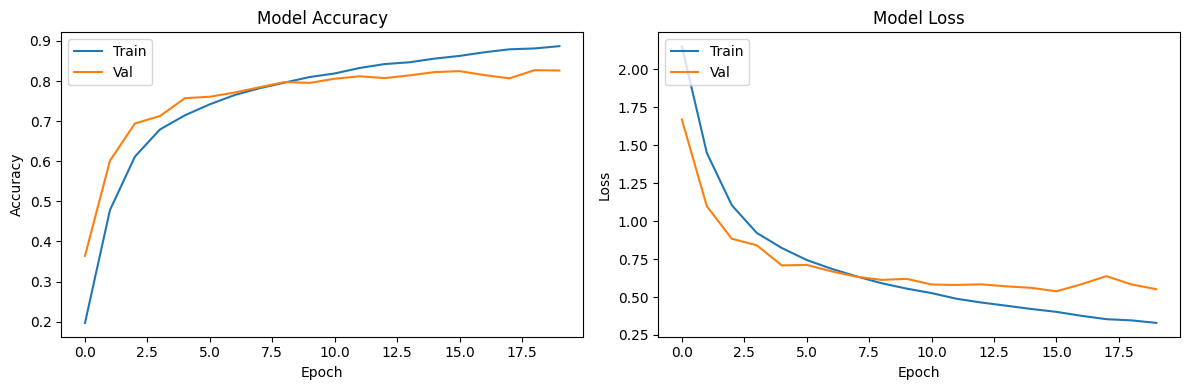

In [10]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='upper left')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='upper left')

plt.tight_layout()
plt.show()

## #32 Transfer Learning

In [ ]:
import tensorflow as tf
import tensorflow_hub as hub

from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
import matplotlib.pyplot as plt

In [ ]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
assert X_train.shape == (50000, 32, 32, 3)
assert X_test.shape == (10000, 32, 32, 3)
assert y_train.shape == (50000, 1)
assert y_test.shape == (10000, 1)

In [ ]:
# Convert the data to TensorFlow Datasets
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))

# Preprocessing function
def preprocess(image, label):
    image = tf.cast(image, tf.float32)
    image = (image / 255.0)
    image = tf.image.resize(image, (224,224))
    return image, label

# Dataset preparation function with augmentation option
def prepare_dataset(ds, batch_size=20):
    ds = ds.map(preprocess, num_parallel_calls=tf.data.experimental.AUTOTUNE)
    ds = ds.shuffle(buffer_size=10000).batch(batch_size)
    ds = ds.prefetch(buffer_size=tf.data.experimental.AUTOTUNE)
    return ds

# Preprocess the data
train_ds = prepare_dataset(train_ds)
test_ds = prepare_dataset(test_ds)

In [ ]:
model_url = "https://www.kaggle.com/models/google/efficientnet-v2/TensorFlow2/imagenet1k-b0-feature-vector/2"

model = tf.keras.Sequential(
    [
        hub.KerasLayer(model_url, trainable=False, input_shape=(224, 224, 3), name="feature_extraction_layer"),
        tf.keras.layers.Dropout(rate=0.2),
        tf.keras.layers.Dense(128, activation="relu", kernel_initializer="he_normal"),
        tf.keras.layers.Dropout(rate=0.2),
        tf.keras.layers.Dense(10, activation="softmax")
    ]
)

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

In [ ]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 feature_extraction_layer (K  (None, 1280)             5919312   
 erasLayer)                                                      
                                                                 
 dropout (Dropout)           (None, 1280)              0         
                                                                 
 dense (Dense)               (None, 128)               163968    
                                                                 
 dropout_1 (Dropout)         (None, 128)               0         
                                                                 
 dense_1 (Dense)             (None, 10)                1290      
                                                                 
Total params: 6,084,570
Trainable params: 165,258
Non-trainable params: 5,919,312
________________________________________

In [ ]:
# Train the model
history = model.fit(
    train_ds, epochs=100, validation_data=test_ds, batch_size=20)

Epoch 1/100
2500/2500 [==============================] - 276s 103ms/step - loss: 0.8046 - accuracy: 0.7204 - val_loss: 0.5977 - val_accuracy: 0.7916
Epoch 2/100
2500/2500 [==============================] - 262s 104ms/step - loss: 0.6530 - accuracy: 0.7723 - val_loss: 0.5538 - val_accuracy: 0.8098
Epoch 3/100
2500/2500 [==============================] - 257s 101ms/step - loss: 0.6072 - accuracy: 0.7885 - val_loss: 0.5568 - val_accuracy: 0.8054
Epoch 4/100
2500/2500 [==============================] - 252s 100ms/step - loss: 0.5768 - accuracy: 0.7984 - val_loss: 0.5244 - val_accuracy: 0.8181
Epoch 5/100
2500/2500 [==============================] - 255s 100ms/step - loss: 0.5591 - accuracy: 0.8049 - val_loss: 0.5197 - val_accuracy: 0.8184
Epoch 6/100
2500/2500 [==============================] - 250s 99ms/step - loss: 0.5386 - accuracy: 0.8099 - val_loss: 0.5033 - val_accuracy: 0.8248
Epoch 7/100
2500/2500 [==============================] - 251s 100ms/step - loss: 0.5259 - accuracy: 0.8141 

In [ ]:
# Plot training & validation accuracy values
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')

plt.tight_layout()
plt.show()

## #33 CIFAR-10 Project

In [2]:
import tensorflow as tf

In [ ]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
assert X_train.shape == (50000, 32, 32, 3)
assert X_test.shape == (10000, 32, 32, 3)
assert y_train.shape == (50000, 1)
assert y_test.shape == (10000, 1)

In [6]:
def preprocess_image_input(input_images):
    input_images = input_images.astype('float32')
    output_ims = tf.keras.applications.xception.preprocess_input(input_images)
    return output_ims


X_train = preprocess_image_input(X_train)
X_test = preprocess_image_input(X_test)

In [ ]:
inputs = tf.keras.layers.Input(shape=(32, 32, 3), name='input_layer')
resize = tf.keras.layers.UpSampling2D(size=(7, 7), name='resize_layer')(inputs)
feature_extractor = tf.keras.applications.Xception(input_shape=(224, 224, 3), include_top=False, weights='imagenet')(resize)
x = tf.keras.layers.GlobalAveragePooling2D(name='global_avg_pool_layer')(feature_extractor)
x = tf.keras.layers.Flatten(name='flatten_layer')(x)
x = tf.keras.layers.Dense(1024, activation='relu', name='dense_layer_1', kernel_initializer='he_normal')(x)
x = tf.keras.layers.Dense(512, activation='relu', name='dense_layer_2', kernel_initializer='he_normal')(x)
classification_output = tf.keras.layers.Dense(10, activation='softmax', name='output_layer')(x)

model = tf.keras.Model(inputs, outputs=classification_output, name='my_model')
model.compile(optimizer=tf.keras.optimizers.Adam(), loss=tf.keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])
model.summary()

83683744/83683744 [==============================] - 188s 2us/step
Model: "my_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_layer (InputLayer)    [(None, 32, 32, 3)]       0         
                                                                 
 resize_layer (UpSampling2D)  (None, 224, 224, 3)      0         
                                                                 
 xception (Functional)       (None, 7, 7, 2048)        20861480  
                                                                 
 global_avg_pool_layer (Glob  (None, 2048)             0         
 alAveragePooling2D)                                             
                                                                 
 flatten_layer (Flatten)     (None, 2048)              0         
                                                                 
 dense_layer_1 (Dense)       (None, 1024)              20

In [ ]:
history = model.fit(X_train, y_train, epochs=5, validation_data=(X_test, y_test))

In [10]:
for layer in model.layers:
    print(layer, layer.trainable)

<keras.engine.input_layer.InputLayer object at 0x0000024AE12EFC70> True
<keras.layers.reshaping.up_sampling2d.UpSampling2D object at 0x0000024AE12EFD00> True
<keras.engine.functional.Functional object at 0x0000024AAAAD7640> True
<keras.layers.pooling.global_average_pooling2d.GlobalAveragePooling2D object at 0x0000024ADF168730> True
<keras.layers.reshaping.flatten.Flatten object at 0x0000024AAAAD74F0> True
<keras.layers.core.dense.Dense object at 0x0000024AB11BA730> True
<keras.layers.core.dense.Dense object at 0x0000024AAAAA9100> True
<keras.layers.core.dense.Dense object at 0x0000024AAAC7F7C0> True


In [11]:
len(model.layers[2].layers)

132

In [12]:
for layer in model.layers[2].layers[:100]:
    layer.trainable = False # Freeze the layers

In [ ]:
model.fit(X_train, y_train, epochs=2, validation_data=(X_test, y_test))

## #35 U-Net Project

In [8]:
import tensorflow as tf
# import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

from keras.models import Model
from keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, concatenate, Conv2DTranspose, Dropout

In [ ]:
dataset, info = tfds.load('oxford_iiit_pet:3.*.*', with_info=True)

In [9]:
def normalize(input_image, input_mask):
  input_image = tf.cast(input_image, tf.float32) / 255.0
  input_mask -= 1
  return input_image, input_mask

In [10]:
def load_image(datapoint):
  input_image = tf.image.resize(datapoint['image'], (128, 128))
  input_mask = tf.image.resize(
    datapoint['segmentation_mask'],
    (128, 128),
    method = tf.image.ResizeMethod.NEAREST_NEIGHBOR,
  )

  input_image, input_mask = normalize(input_image, input_mask)

  return input_image, input_mask

In [ ]:
TRAIN_LENGTH = info.splits['train'].num_examples
BATCH_SIZE = 64
BUFFER_SIZE = 1000
STEPS_PER_EPOCH = TRAIN_LENGTH // BATCH_SIZE

In [ ]:
train_images = dataset['train'].map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
test_images = dataset['test'].map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

In [ ]:
class Augment(tf.keras.layers.Layer):
  def __init__(self, seed=42):
    super().__init__()
    self.augment_inputs = tf.keras.layers.RandomFlip(mode="horizontal", seed=seed)
    self.augment_labels = tf.keras.layers.RandomFlip(mode="horizontal", seed=seed)

  def call(self, inputs, labels):
    inputs = self.augment_inputs(inputs)
    labels = self.augment_labels(labels)
    return inputs, labels

In [ ]:
train_batches = (
    train_images
    .cache()
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE)
    .repeat()
    .map(Augment())
    .prefetch(buffer_size=tf.data.AUTOTUNE))

test_batches = test_images.batch(BATCH_SIZE)

In [ ]:
def display(display_list):
  plt.figure(figsize=(15, 15))

  title = ['Input Image', 'True Mask', 'Predicted Mask']

  for i in range(len(display_list)):
    plt.subplot(1, len(display_list), i+1)
    plt.title(title[i])
    plt.imshow(tf.keras.utils.array_to_img(display_list[i]))
    plt.axis('off')
  plt.show()

In [ ]:
for images, masks in train_batches.take(2):
  sample_image, sample_mask = images[0], masks[0]
  display([sample_image, sample_mask])

In [ ]:
from IPython.display import Image

# Inspired by the paper "U-Net: Convolutional Networks for Biomedical Image Segmentation" (https://arxiv.org/abs/1505.04597)


# Display image
Image(filename='unet.png', width=1200)

In [5]:
def conv2d_block(input_tensor, num_filters):
    """Function to add 2 convolutional layers with the parameters passed to it"""
    x = Conv2D(num_filters, (3, 3), 1, 'same', activation='relu', kernel_initializer='he_normal')(input_tensor)
    x = Dropout(0.1)(x)
    x = Conv2D(num_filters, (3, 3), 1, 'same', activation='relu', kernel_initializer='he_normal')(x)
    return x

def encoder_block(inputs, num_filters):
    """Function to add 2 convolutional blocks and then perform max pooling on it."""
    conv_block = conv2d_block(inputs, num_filters)
    x = MaxPooling2D((2, 2))(conv_block)
    return conv_block, x

def decoder_block(input_tensor, concat_tensor, num_filters):
    """"Function to perform an upconvolution and then concatenate the result with the shortcut from encoder, followed by 2 convolution blocks."""
    x = Conv2DTranspose(num_filters, (2, 2), 2, 'same')(input_tensor)
    x = concatenate([x, concat_tensor])
    x = conv2d_block(x, num_filters)
    return x

# Build U-Net model
inputs = Input((128, 128, 3))
s = inputs

# Encoder
encoder1_block, pool1 = encoder_block(s, 16)
encoder2_block, pool2 = encoder_block(pool1, 32)
encoder3_block, pool3 = encoder_block(pool2, 64)
encoder4_block, pool4 = encoder_block(pool3, 128)

# Bridge
bridge = conv2d_block(pool4, 256)

# Decoder
decoder1_block = decoder_block(bridge, encoder4_block, 128)
decoder2_block = decoder_block(decoder1_block, encoder3_block, 64)
decoder3_block = decoder_block(decoder2_block, encoder2_block, 32)
decoder4_block = decoder_block(decoder3_block, encoder1_block, 16)

outputs = Conv2D(3, (1, 1), 1, activation='softmax')(decoder4_block)
model = Model(inputs=[inputs], outputs=[outputs])
model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])

In [6]:
model.summary()

Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_3 (InputLayer)           [(None, 128, 128, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d_29 (Conv2D)             (None, 128, 128, 16  448         ['input_3[0][0]']                
                                )                                                                 
                                                                                                  
 dropout_14 (Dropout)           (None, 128, 128, 16  0           ['conv2d_29[0][0]']              
                                )                                                           

In [ ]:
tf.keras.utils.plot_model(model, show_shapes=True, expand_nested=True)

In [ ]:
def create_mask(pred_mask):
  pred_mask = tf.math.argmax(pred_mask, axis=-1)
  pred_mask = pred_mask[..., tf.newaxis]
  return pred_mask[0]

def show_predictions(dataset=None, num=1):
  if dataset:
    for image, mask in dataset.take(num):
      pred_mask = model.predict(image)
      display([image[0], mask[0], create_mask(pred_mask)])
  else:
    display([sample_image, sample_mask,
             create_mask(model.predict(sample_image[tf.newaxis, ...]))])
show_predictions()

In [ ]:
from IPython.display import clear_output

class DisplayCallback(tf.keras.callbacks.Callback):
  def on_epoch_end(self, epoch, logs=None):
    clear_output(wait=True)
    show_predictions()
    print (f'\nSample Prediction after epoch {epoch+1}\n')

In [ ]:
EPOCHS = 50
VAL_SUBSPLITS = 5
VALIDATION_STEPS = info.splits['test'].num_examples//BATCH_SIZE//VAL_SUBSPLITS

model_history = model.fit(train_batches, epochs=EPOCHS, steps_per_epoch=STEP_PER_EPOCH,
                          validation_steps=VALIDATION_STEPS, validation_data=test_batches, callbacks=[DisplayCallback()])

In [ ]:
loss = model_history.history['loss']
val_loss = model_history.history['val_loss']

plt.figure()
plt.plot(model_history.epoch, loss, 'r', label='Training loss')
plt.plot(model_history.epoch, val_loss, 'bo', label='Validation loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss Value')
plt.ylim([0, 1])
plt.legend()
plt.show()

In [ ]:
show_predictions(test_batches, 3)